# **DEEP LEARNING with TensorFlow 2 and tf.keras**

# 1. TensorFlow 2 and tf.keras


## 1.1. What Are Keras and tf.keras?

[Keras](https://keras.io/) is an open-source deep learning library written in Python. The project was started in 2015 by Francois Chollet. It quickly became a popular framework for developers, becoming one of, if not the most, popular deep learning libraries.

During the period of 2015-2019, developing deep learning models using mathematical libraries like TensorFlow, Theano, and PyTorch was cumbersome, requiring tens or even hundreds of lines of code to achieve the simplest tasks. Keras was popular because the API was clean and simple, allowing standard deep learning models to be defined, fit, and evaluated in just a few lines of code. 

A secondary reason Keras took-off was because it allowed you to use any one among the range of popular deep learning mathematical libraries as the backend (e.g. used to perform the computation), such as [TensorFlow](https://github.com/tensorflow/tensorflow), [Theano](https://github.com/Theano/Theano), and later, [CNTK](https://github.com/microsoft/CNTK). This allowed the power of these libraries to be harnessed (e.g. GPUs) with a very clean and simple interface.

In 2019, Google released a new version of their TensorFlow deep learning library (**TensorFlow 2**) that integrated the Keras API directly and promoted this interface as the default or standard interface for deep learning development on the platform.

This integration is commonly referred to as the *tf.keras* interface or API (“*tf*” is short for “*TensorFlow*“). This is to distinguish it from the so-called standalone Keras open source project.

* **Standalone Keras**. The standalone open source project that supports TensorFlow, Theano and CNTK backends.
* **tf.keras**. The Keras API integrated into TensorFlow 2.

The Keras API implementation in Keras is referred to as “*tf.keras*” because this is the Python idiom used when referencing the API. First, the TensorFlow module is imported and named “*tf*“; then, Keras API elements are accessed via calls to *tf.keras*; for example:


In [3]:
# example of tf.keras python idiom
import tensorflow as tf
# use keras API
model = tf.keras.Sequential()

Given that TensorFlow was the de facto standard backend for the Keras open source project, the integration means that a single library can now be used instead of two separate libraries. Further, the standalone Keras project now recommends all future Keras development use the *tf.keras* API.


> ***At this time, we recommend that Keras users who use multi-backend Keras with the TensorFlow backend switch to tf.keras in TensorFlow 2.0. tf.keras is better maintained and has better integration with TensorFlow features (eager execution, distribution support and other).***

— [*Keras Project Homepage,*](https://keras.io/) Accessed December 2019.

## 1.2. Installing TensorFlow 2

There are many ways to install the TensorFlow open-source deep learning library. you can see a complete list of installation instructions here:

[Install TensorFlow 2 Guide](https://www.tensorflow.org/install)

Once TensorFlow is installed, it is **important to confirm** that the library was installed successfully and that you can start using it.

In order to check the version you should run the following commands:

In [4]:
# check version
import tensorflow
print(tensorflow.__version__)

2.21.0


 If TensorFlow is installed correctly, you should see the output like the following:


> 2.0.0



# 2. Deep Learning Model Life-Cycle

In this section, you will discover the life-cycle for a deep learning model and the two *tf.keras* APIs that you can use to define models

## 2.1.The 5-Step Model Life-Cycle

A model has a life-cycle, and this very simple knowledge provides the backbone for both modeling a dataset and understanding the tf.keras API.

The five steps in the life-cycle are as follows:

1.   Define the model.
1.   Compile the model.
2.   Fit the model.
1.   Evaluate the model.
2.   Make predictions.

Let’s take a closer look at each step in turn.

### Define the Model
Defining the model requires that you first select the type of model that you need and then choose the architecture or network topology.

From an API perspective, this involves defining the layers of the model, configuring each layer with a number of nodes and activation function, and connecting the layers together into a cohesive model.

Models can be defined either with the Sequential API or the Functional API, and we will take a look at this in the next section.


In [5]:
...
# define the model
# model = ...
model = tf.keras.Sequential()

### Compile the Model

Compiling the model requires that you first select a loss function that you want to optimize, such as mean squared error or cross-entropy.

It also requires that you select an algorithm to perform the optimization procedure, typically stochastic gradient descent, or a modern variation, such as Adam. It may also require that you select any performance metrics to keep track of during the model training process.

From an API perspective, this involves calling a function to compile the model with the chosen configuration, which will prepare the appropriate data structures required for the efficient use of the model you have defined.

* The **optimizer** can be specified as a string for a known optimizer class, e.g. ‘*sgd*‘ for stochastic gradient descent, or you can configure an instance of an optimizer class and use that. For a list of supported optimizers, see: [tf.keras.optimizers](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers). 
* The three most common **loss functions** are: ‘*binary_crossentropy*‘ for binary classification, * ‘*sparse_categorical_crossentropy*‘ for multi-class classification and ‘*mse*‘ (mean squared error) for regression. For a list of supported loss functions, see: [tf.keras Loss Functions](https://www.tensorflow.org/api_docs/python/tf/keras/losses)
* **Metrics** are defined as a list of strings for known metric functions or a list of functions to call to evaluate predictions.For a list of supported metrics, see: [tf.keras Metrics](https://www.tensorflow.org/api_docs/python/tf/keras/metrics)

In [6]:
import tensorflow as tf
...
# an example of how to compile the model
opt = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(optimizer=opt, loss='binary_crossentropy')
...
# another way to compile the model
model.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

E0000 00:00:1780386618.752370    5575 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Fit the Model

Fitting the model requires that you first select the training configuration, such as the **number of epochs** (loops through the training dataset) and the **batch size** (number of samples in an epoch used to estimate model error).

Training applies the chosen optimization algorithm to minimize the chosen loss function and updates the model using the backpropagation of error algorithm.

Fitting the model is the slow part of the whole process and can take seconds to hours to days, depending on the complexity of the model, the hardware you’re using, and the size of the training dataset.

From an API perspective, this involves calling a function to perform the training process. This function will block (not return) until the training process has finished.

While fitting the model, a progress bar will summarize the status of each epoch and the overall training process. This can be simplified to a simple report of model performance each epoch by setting the “verbose” argument to 2. All output can be turned off during training by setting “verbose” to 0.


In [7]:
...
# fit the model. X is the vector of training data objects, y is the class vector
model.fit(X, y, epochs=100, batch_size=32, verbose=0)

NameError: name 'X' is not defined

### Evaluate the Model

Evaluating the model requires that you first choose a holdout dataset used to evaluate the model. This should be data not used in the training process so that we can get an unbiased estimate of the performance of the model when making predictions on new data.

The speed of model evaluation is proportional to the amount of data you want to use for the evaluation, although it is much faster than training as the model is not changed.

From an API perspective, this involves calling a function with the testing dataset and getting a loss and perhaps other metrics that can be reported.

In [0]:
...
# evaluate the model
loss = model.evaluate(X, y, verbose=0)

### Make a Prediction

Making a prediction is the final step in the life-cycle. It is why we wanted the model in the first place.

It requires you have new data for which a prediction is required, e.g. where you do not have the target values.

From an API perspective, you simply call a function to make a prediction of a class label, probability, or numerical value: whatever you designed your model to predict.

You may want to save the model and later load it to make predictions. You may also choose to fit a model on all of the available data before you start using it.

Now that we are familiar with the model life-cycle, let’s take a look at the two main ways to use the tf.keras API to build models: sequential and functional.

In [0]:
...
# make a prediction
yhat = model.predict(X)

## 2.2. Sequential Model API (Simple)

The sequential model API is one of the simplest API. It is referred to as “sequential” because it involves defining a Sequential class and adding layers to the model one by one in a linear manner, from input to output.

The example below defines a Sequential MLP model that accepts eight inputs, has one hidden layer with 10 nodes and then an output layer with one node to predict a numerical value.

In [0]:
# example of a model defined with the sequential api
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
# define the model
model = Sequential()
model.add(Dense(10, input_shape=(8,)))
model.add(Dense(1))

Note that the visible layer of the network is defined by the “input_shape” argument on the first hidden layer. That means in the above example, the model expects the input for one sample to be a vector of eight numbers.

The sequential API is easy to use because you keep calling model.add() until you have added all of your layers.

For example, here is a deep MLP with five hidden layers.

In [0]:
# example of a model defined with the sequential api
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
# define the model
model = Sequential()
model.add(Dense(100, input_shape=(8,)))
model.add(Dense(80))
model.add(Dense(30))
model.add(Dense(10))
model.add(Dense(5))
model.add(Dense(1))

## 2.3. Functional Model API (Advanced)
The functional API is more complex but is also more flexible.
It involves explicitly connecting the output of one layer to the input of another layer. Each connection is specified.

* First, an input layer must be defined via the Input class, and the shape of an input sample is specified. We must retain a reference to the input layer when defining the model.
* Next, a fully connected layer can be connected to the input by calling the layer and passing the input layer. This will return a reference to the output connection in this new layer.
* Once connected, we define a Model object and specify the input and output layers. The complete example is listed below.

In [0]:
# example of a model defined with the functional api
from tensorflow.keras import Model
from tensorflow.keras import Input
from tensorflow.keras.layers import Dense
# define the layers
x_in = Input(shape=(8,))
x = Dense(10)(x_in)
x_out = Dense(1)(x)
# define the model
model = Model(inputs=x_in, outputs=x_out)

As such, it allows for more complicated model designs, such as models that may have multiple input paths (separate vectors) and models that have multiple output paths (e.g. a word and a number).

The functional API can be a lot of fun when you get used to it.

For more on the functional API, see: [The Keras functional API in TensorFlow](https://www.tensorflow.org/guide/keras/functional)

Now that we are familiar with the model life-cycle and the two APIs that can be used to define models, let’s look at developing some standard models.

# 3. Developing Deep Learning Models
In this section, you will discover how to develop, evaluate, and make predictions with standard deep learning models, including Multilayer Perceptrons (MLP), Convolutional Neural Networks (CNNs), and Recurrent Neural Networks (RNNs).

## 3.1. Develop Multilayer Perceptron Models
A Multilayer Perceptron model, or MLP for short, is a standard fully connected neural network model.

It is comprised of layers of nodes where each node is connected to all outputs from the previous layer and the output of each node is connected to all inputs for nodes in the next layer.

An MLP is created by with one or more *Dense* layers. This model is appropriate for tabular data, that is data as it looks in a table or spreadsheet with one column for each variable and one row for each variable. There are three predictive modeling problems you may want to explore with an MLP; they are binary classification, multiclass classification, and regression.

Let’s fit a model on a real dataset for each of these cases.

Note, the models in this section are effective, but not optimized. See if you can improve their performance. Post your findings in the comments below.

### MLP for Binary Classification

We will use the Ionosphere binary (two-class) classification dataset to demonstrate an MLP for binary classification.

This dataset involves predicting whether a structure is in the atmosphere or not given radar returns.

The dataset will be downloaded automatically using [Pandas](https://pandas.pydata.org/), but you can learn more about it here.

*  [Ionosphere Dataset (csv)](https://raw.githubusercontent.com/jbrownlee/Datasets/master/ionosphere.csv).
* [Ionosphere Dataset Description (csv)](https://raw.githubusercontent.com/jbrownlee/Datasets/master/ionosphere.names).

We will use a [LabelEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html) to encode the string labels to integer values 0 and 1. The model will be fit on 67 percent of the data, and the remaining 33 percent will be used for evaluation, split using the [train_test_split()](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function.

It is a good practice to use ‘relu‘ activation with a ‘he_normal‘ weight initialization. This combination goes a long way to overcome the problem of vanishing gradients when training deep neural network models. For more on ReLU, see the tutorial: 
[A Gentle Introduction to the Rectified Linear Unit (ReLU)](https://machinelearningmastery.com/rectified-linear-activation-function-for-deep-learning-neural-networks/).

The model predicts the probability of class 1 and uses the sigmoid activation function. The model is optimized using the adam version of stochastic gradient descent and seeks to minimize the cross-entropy loss.

The complete example is listed below.

In [8]:
# mlp for binary classification
  from pandas import read_csv
  from sklearn.model_selection import train_test_split
  from sklearn.preprocessing import LabelEncoder
  from tensorflow.keras import Sequential
  from tensorflow.keras.layers import Dense
# load the dataset
  path = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/ionosphere.csv'
  df = read_csv(path, header=None)
# split into input and output columns
  X, y = df.values[:, :-1], df.values[:, -1]
# ensure all data are floating point values
  X = X.astype('float32')
# encode strings to integer
  y = LabelEncoder().fit_transform(y)
# split into train and test datasets
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
  print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
# determine the number of input features
  n_features = X_train.shape[1]
# define model
  model = Sequential()
  model.add(Dense(10, activation='relu', kernel_initializer='he_normal', input_shape=(n_features,)))
  model.add(Dense(8, activation='relu', kernel_initializer='he_normal'))
  model.add(Dense(1, activation='sigmoid'))
# compile the model
  model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# fit the model
  model.fit(X_train, y_train, epochs=150, batch_size=32, verbose=0)
# evaluate the model
  loss, acc = model.evaluate(X_test, y_test, verbose=0)
  print('Test Accuracy: %.3f' % acc)
# make a prediction
  row = [1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1,0.03760,0.85243,-0.17755,0.59755,-0.44945,0.60536,-0.38223,0.84356,-0.38542,0.58212,-0.32192,0.56971,-0.29674,0.36946,-0.47357,0.56811,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300]
  yhat = model.predict([row])
  print('Predicted: %.3f' % yhat)

IndentationError: unexpected indent (2233001384.py, line 2)

Running the example first reports the shape of the dataset, then fits the model and evaluates it on the test dataset. Finally, a prediction is made for a single row of data.

Your specific results will vary given the stochastic nature of the learning algorithm. Try running the example a few times.

What results did you get? Can you change the model to do better?
Post your findings to the comments below.

In this case, we can see that the model achieved a classification accuracy of about 94 percent and then predicted a probability of 0.9 that the one row of data belongs to class 1.

### MLP for Multiclass Classification

We will use the Iris flowers multiclass classification dataset to demonstrate an MLP for multiclass classification.

This problem involves predicting the species of iris flower given measures of the flower.

The dataset will be downloaded automatically using Pandas, but you can learn more about it here.

* [Iris Dataset (csv).](https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.csv)
* [Iris Dataset Description (csv).](https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.names)

Given that it is a multiclass classification, the model must have one node for each class in the output layer and use the softmax activation function. The loss function is the ‘*sparse_categorical_crossentropy*‘, which is appropriate for integer encoded class labels (e.g. 0 for one class, 1 for the next class, etc.)

The complete example of fitting and evaluating an MLP on the iris flowers dataset is listed below.

In [0]:
# mlp for multiclass classification
from numpy import argmax
from pandas import read_csv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
# load the dataset
path = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.csv'
df = read_csv(path, header=None)
# split into input and output columns
X, y = df.values[:, :-1], df.values[:, -1]
# ensure all data are floating point values
X = X.astype('float32')
# encode strings to integer
y = LabelEncoder().fit_transform(y)
# split into train and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
# determine the number of input features
n_features = X_train.shape[1]
# define model
model = Sequential()
model.add(Dense(10, activation='relu', kernel_initializer='he_normal', input_shape=(n_features,)))
model.add(Dense(8, activation='relu', kernel_initializer='he_normal'))
model.add(Dense(3, activation='softmax'))
# compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# fit the model
model.fit(X_train, y_train, epochs=150, batch_size=32, verbose=0)
# evaluate the model
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print('Test Accuracy: %.3f' % acc)
# make a prediction
row = [5.1,3.5,1.4,0.2]
yhat = model.predict([row])
print('Predicted: %s (class=%d)' % (yhat, argmax(yhat)))

(100, 4) (50, 4) (100,) (50,)
Test Accuracy: 0.920
Predicted: [[0.950693   0.02420473 0.02510224]] (class=0)


Running the example first reports the shape of the dataset, then fits the model and evaluates it on the test dataset. Finally, a prediction is made for a single row of data.

Your specific results will vary given the stochastic nature of the learning algorithm. Try running the example a few times.

What results did you get? Can you change the model to do better?
Post your findings to the comments below.

In this case, we can see that the model achieved a classification accuracy of about 98 percent and then predicted a probability of a row of data belonging to each class, although class 0 has the highest probability.

### MLP for Regression
We will use the Boston housing regression dataset to demonstrate an MLP for regression predictive modeling.

This problem involves predicting house value based on properties of the house and neighborhood.

The dataset will be downloaded automatically using Pandas, but you can learn more about it here.

* [Boston Housing Dataset (csv).](https://raw.githubusercontent.com/jbrownlee/Datasets/master/housing.csv)
* [Boston Housing Dataset Description (csv).](https://raw.githubusercontent.com/jbrownlee/Datasets/master/housing.names)

This is a regression problem that involves predicting a single numerical value. As such, the output layer has a single node and uses the default or linear activation function (no activation function). The mean squared error (mse) loss is minimized when fitting the model.

Recall that this is a regression, not classification; therefore, we cannot calculate classification accuracy. The complete example of fitting and evaluating an MLP on the Boston housing dataset is listed below.

In [0]:
# mlp for regression
from numpy import sqrt
from pandas import read_csv
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
# load the dataset
path = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/housing.csv'
df = read_csv(path, header=None)
# split into input and output columns
X, y = df.values[:, :-1], df.values[:, -1]
# split into train and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
# determine the number of input features
n_features = X_train.shape[1]
# define model
model = Sequential()
model.add(Dense(10, activation='relu', kernel_initializer='he_normal', input_shape=(n_features,)))
model.add(Dense(8, activation='relu', kernel_initializer='he_normal'))
model.add(Dense(1))
# compile the model
model.compile(optimizer='adam', loss='mse')
# fit the model
model.fit(X_train, y_train, epochs=150, batch_size=32, verbose=0)
# evaluate the model
error = model.evaluate(X_test, y_test, verbose=0)
print('MSE: %.3f, RMSE: %.3f' % (error, sqrt(error)))
# make a prediction
row = [0.00632,18.00,2.310,0,0.5380,6.5750,65.20,4.0900,1,296.0,15.30,396.90,4.98]
yhat = model.predict([row])
print('Predicted: %.3f' % yhat)

        0     1     2   3      4      5   ...  8      9     10      11    12    13
0  0.00632  18.0  2.31   0  0.538  6.575  ...   1  296.0  15.3  396.90  4.98  24.0
1  0.02731   0.0  7.07   0  0.469  6.421  ...   2  242.0  17.8  396.90  9.14  21.6
2  0.02729   0.0  7.07   0  0.469  7.185  ...   2  242.0  17.8  392.83  4.03  34.7
3  0.03237   0.0  2.18   0  0.458  6.998  ...   3  222.0  18.7  394.63  2.94  33.4
4  0.06905   0.0  2.18   0  0.458  7.147  ...   3  222.0  18.7  396.90  5.33  36.2

[5 rows x 14 columns]
(339, 13) (167, 13) (339,) (167,)
MSE: 33.380, RMSE: 5.778
Predicted: 29.197


Running the example first reports the shape of the dataset then fits the model and evaluates it on the test dataset. Finally, a prediction is made for a single row of data.

Your specific results will vary given the stochastic nature of the learning algorithm. Try running the example a few times.

What results did you get? Can you change the model to do better?
Post your findings to the comments below.

In this case, we can see that the model achieved an MSE of about 60 which is an RMSE of about 7 (units are thousands of dollars). A value of about 26 is then predicted for the single example

## 3.2. Develop Convolutional Neural Network Models

Convolutional Neural Networks, or CNNs for short, are a type of network designed for image input.

They are comprised of models with [convolutional layers](https://machinelearningmastery.com/convolutional-layers-for-deep-learning-neural-networks/) that extract features (called feature maps) and [pooling layers](https://machinelearningmastery.com/pooling-layers-for-convolutional-neural-networks/) that distill features down to the most salient elements.

CNNs are most well-suited to image classification tasks, although they can be used on a wide array of tasks that take images as input.
A popular image classification task is the [MNIST handwritten digit classification](https://en.wikipedia.org/wiki/MNIST_database). It involves tens of thousands of handwritten digits that must be classified as a number between 0 and 9.

The *tf.keras* API provides a convenience function to download and load this dataset directly.

The example below loads the dataset and plots the first few images.

11493376/11490434 [==============================] - 0s 0us/step
Train: X=(60000, 28, 28), y=(60000,)
Test: X=(10000, 28, 28), y=(10000,)


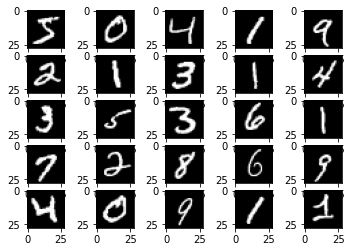

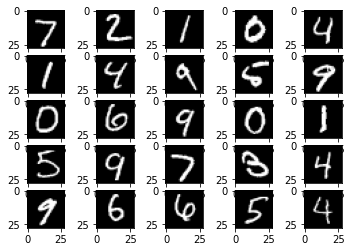

In [0]:
# example of loading and plotting the mnist dataset
from tensorflow.keras.datasets.mnist import load_data
from matplotlib import pyplot
# load dataset
(trainX, trainy), (testX, testy) = load_data()
# summarize loaded dataset
print('Train: X=%s, y=%s' % (trainX.shape, trainy.shape))
print('Test: X=%s, y=%s' % (testX.shape, testy.shape))
# plot first few images
for i in range(25):
	# define subplot
	pyplot.subplot(5, 5, i+1)
	# plot raw pixel data
	pyplot.imshow(trainX[i], cmap=pyplot.get_cmap('gray'))
# show the figure
pyplot.show()

for i in range(25):
	# define subplot
	pyplot.subplot(5, 5, i+1)
	# plot raw pixel data
	pyplot.imshow(testX[i], cmap=pyplot.get_cmap('gray'))
# show the figure
pyplot.show()

We can train a CNN model to classify the images in the MNIST dataset.

Note that the images are arrays of grayscale pixel data; therefore, we must add a channel dimension to the data before we can use the images as input to the model. The reason is that CNN models expect images in a [channels-last format](https://machinelearningmastery.com/a-gentle-introduction-to-channels-first-and-channels-last-image-formats-for-deep-learning/), that is each example to the network has the dimensions [rows, columns, channels], where channels represent the color channels of the image data.

It is also a good idea to scale the pixel values from the default range of 0-255 to 0-1 when training a CNN. For more on scaling pixel values, see the tutorial:

[How to Manually Scale Image Pixel Data for Deep Learning](https://machinelearningmastery.com/how-to-manually-scale-image-pixel-data-for-deep-learning/)

The complete example of fitting and evaluating a CNN model on the MNIST dataset is listed below.

In [0]:
# example of a cnn for image classification
from numpy import unique
from numpy import argmax
from tensorflow.keras.datasets.mnist import load_data
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPool2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout
# load dataset
(x_train, y_train), (x_test, y_test) = load_data()
# reshape data to have a single channel
x_train = x_train.reshape((x_train.shape[0], x_train.shape[1], x_train.shape[2], 1))
x_test = x_test.reshape((x_test.shape[0], x_test.shape[1], x_test.shape[2], 1))
# determine the shape of the input images
in_shape = x_train.shape[1:]
# determine the number of classes
n_classes = len(unique(y_train))
print(in_shape, n_classes)
# normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
# define model
model = Sequential()
model.add(Conv2D(32, (3,3), activation='relu', kernel_initializer='he_uniform', input_shape=in_shape))
model.add(MaxPool2D((2, 2)))
model.add(Flatten())
model.add(Dense(100, activation='relu', kernel_initializer='he_uniform'))
model.add(Dropout(0.5))
model.add(Dense(n_classes, activation='softmax'))
# define loss and optimizer
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# fit the model
model.fit(x_train, y_train, epochs=10, batch_size=128, verbose=0)
# evaluate the model
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print('Accuracy: %.3f' % acc)


(28, 28, 1) 10
Accuracy: 0.987


In [0]:
# make a prediction
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

def plot_image(i, predictions_array, true_label, img):
  predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(img, cmap=plt.get_cmap('gray'))

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(predicted_label,
                                100*np.max(predictions_array),
                                true_label),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array[i], true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

Test object nr 0
[0.08533675 0.08533675 0.08533675 0.08533676 0.08533675 0.08533675
 0.08533675 0.23196931 0.08533675 0.08533675]
7
7


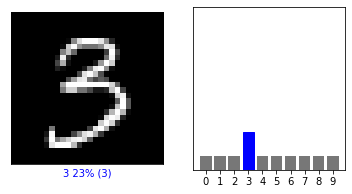

In [0]:
probability_model = tf.keras.Sequential([model,tf.keras.layers.Softmax()])
predictions = probability_model.predict(x_test)

print('Test object nr 0')

print(predictions[0])
print(np.argmax(predictions[0]))
print(y_test[0])

i = 2020
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions, testy, testX)
plt.subplot(1,2,2)
plot_value_array(i, predictions, testy)
plt.show()

Running the example first reports the shape of the dataset, then fits the model and evaluates it on the test dataset. Finally, a prediction is made for a single image.

Your specific results will vary given the stochastic nature of the learning algorithm. Try running the example a few times.

What results did you get? Can you change the model to do better?
Post your findings to the comments below.

First, the shape of each image is reported along with the number of classes; we can see that each image is 28×28 pixels and there are 10 classes as we expected.

In this case, we can see that the model achieved a classification accuracy of about 98 percent on the test dataset. We can then see that the model predicted class 7 for the first image in the testing set.

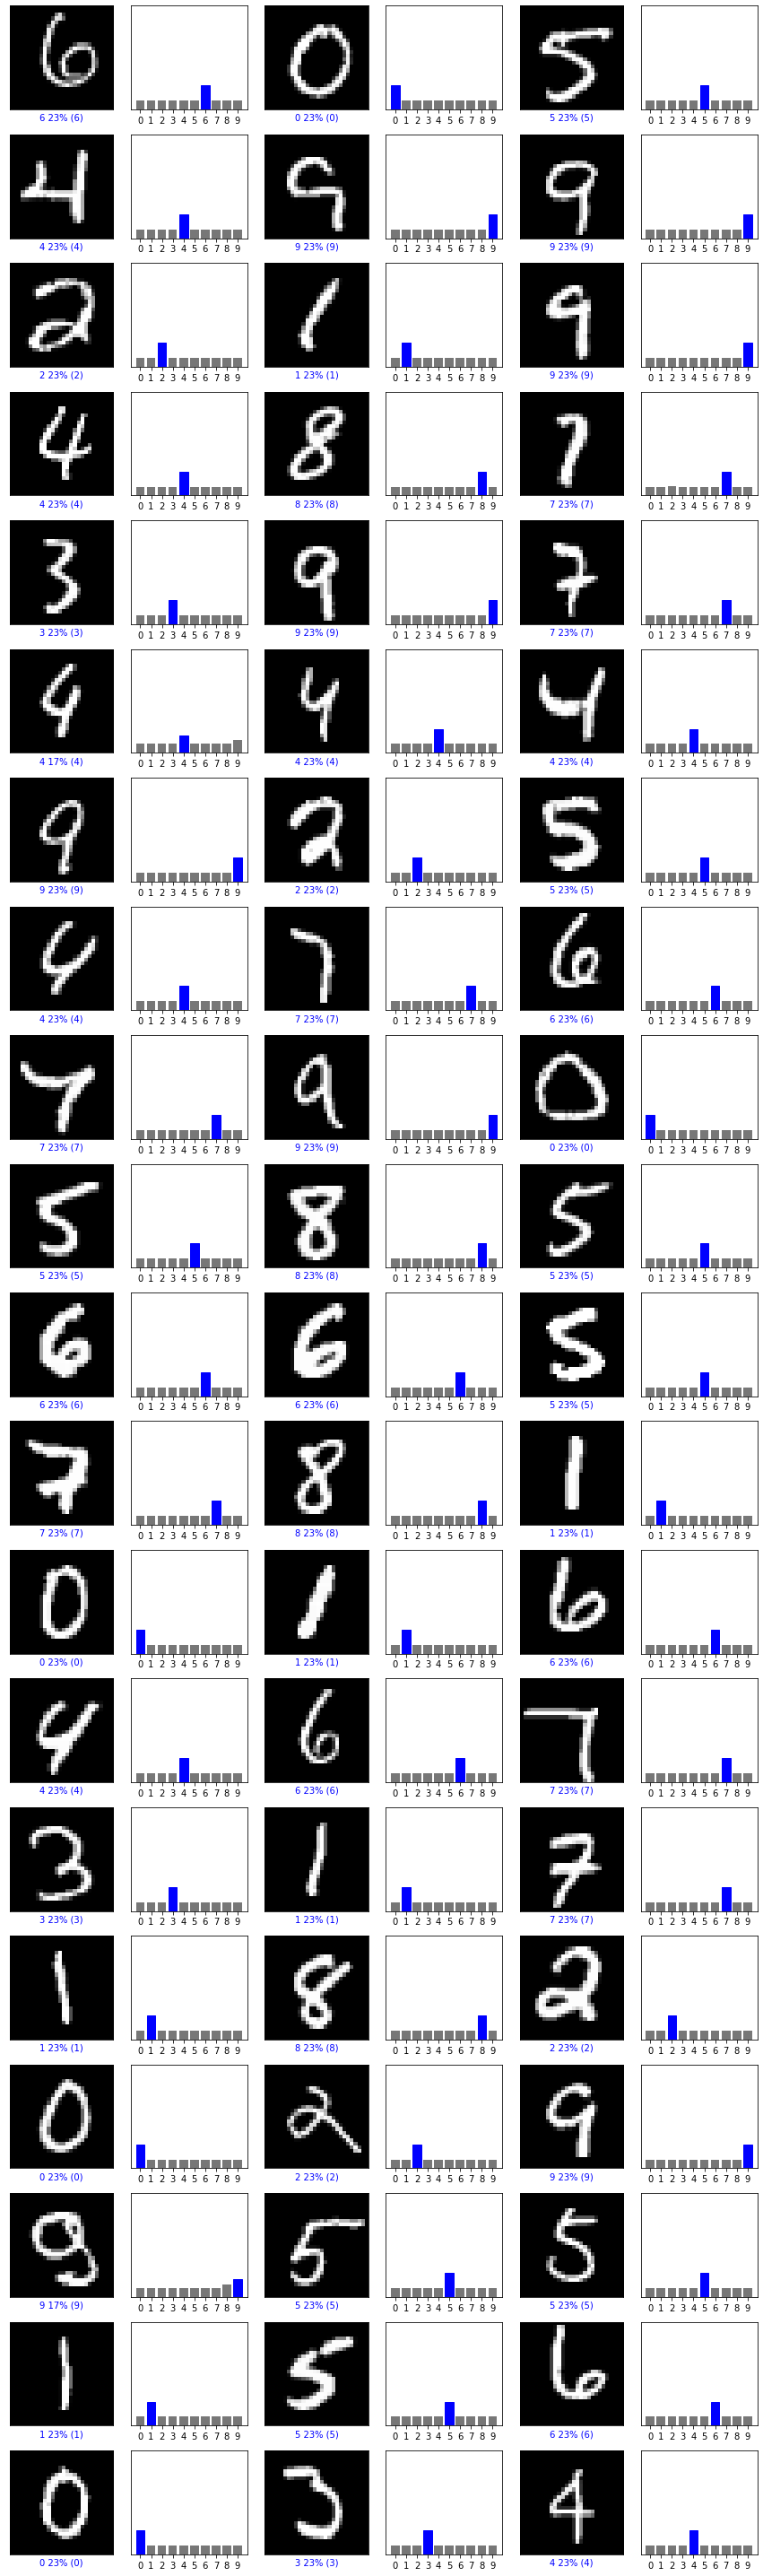

In [0]:
# Plot the first 21 test images, their predicted labels, and the true labels.
# Color correct predictions in blue and incorrect predictions in red.
num_rows = 20
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i+100, predictions, testy, testX)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i+100, predictions, testy)
plt.tight_layout()
plt.show()

WRONGLY CLASSIFIED DIGITS: (true_lebel) -> wrong_label


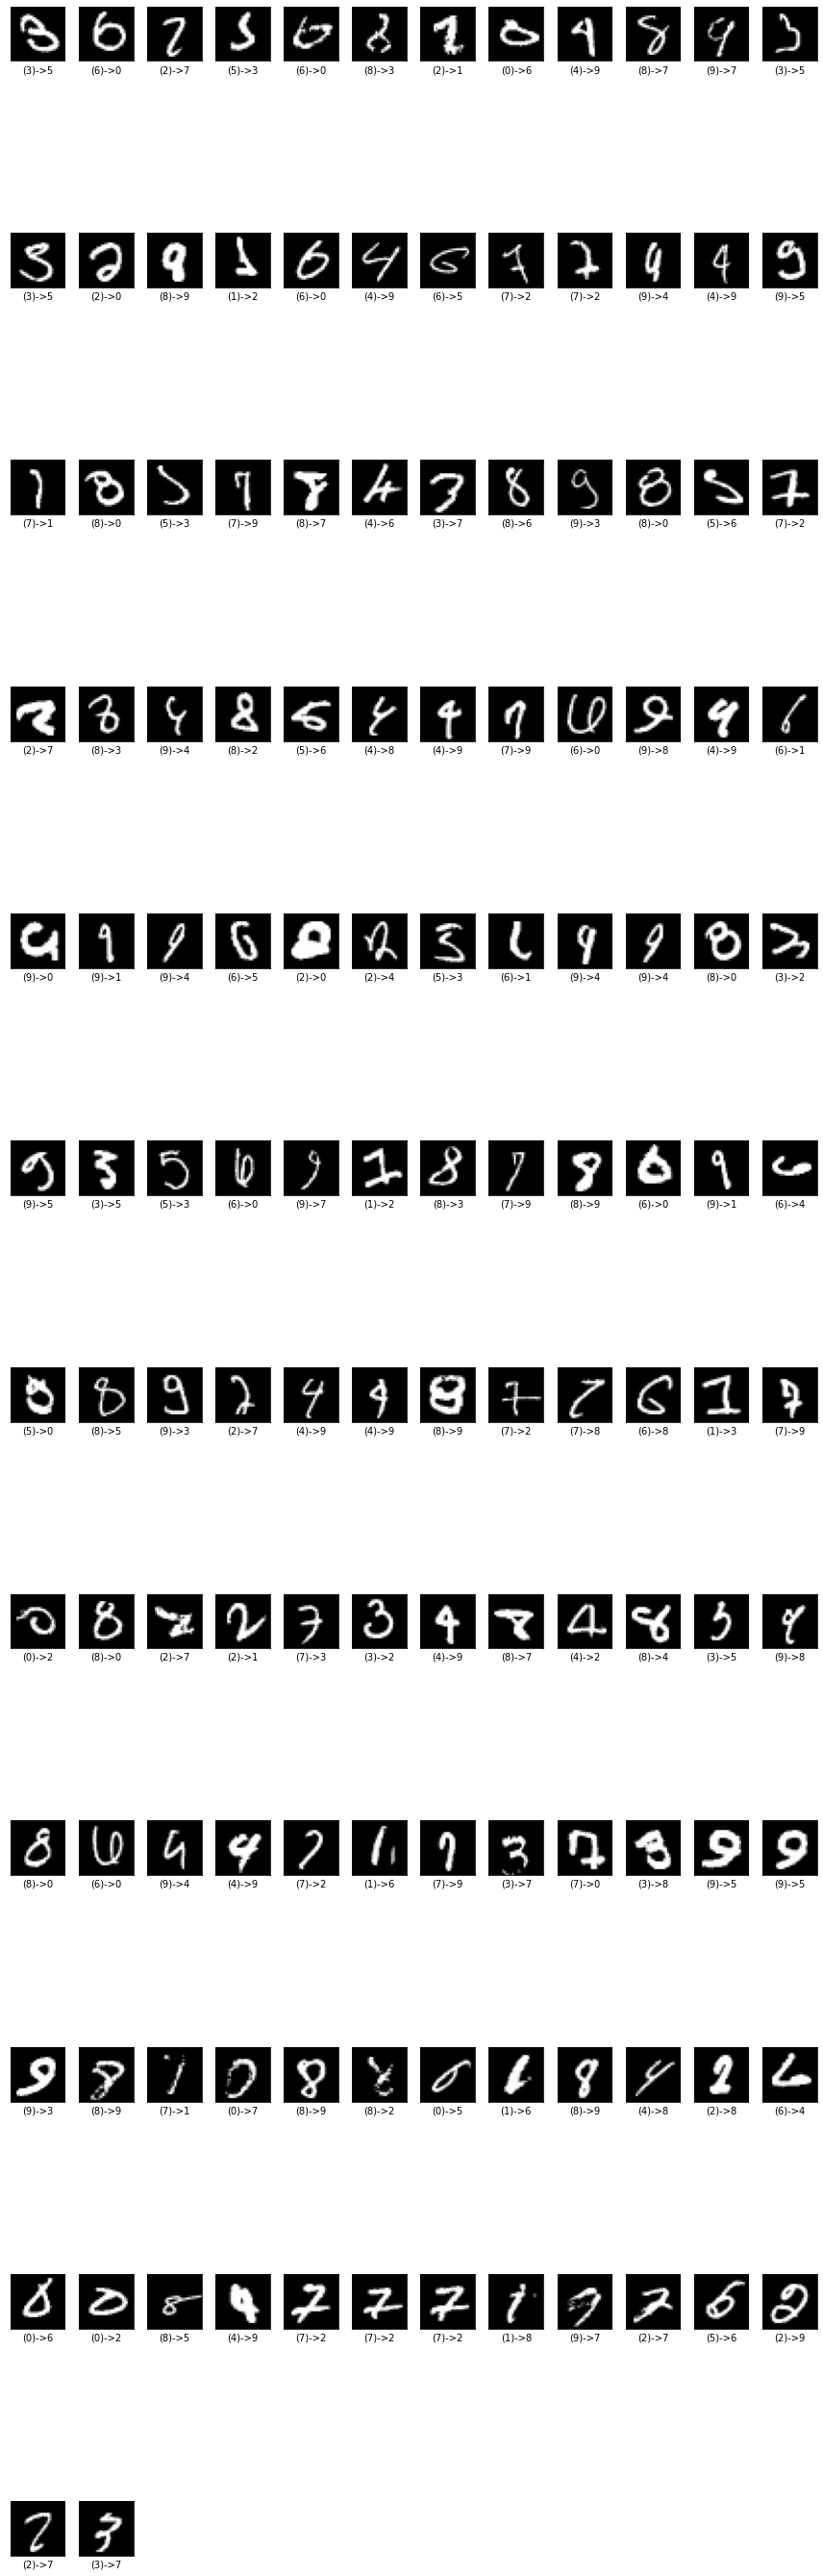

In [0]:
print("WRONGLY CLASSIFIED DIGITS: (true_lebel) -> wrong_label")
sub_i = 0
plt.figure(figsize=(4*num_cols, 2*num_rows))
for i in range(testy.size):
  if np.argmax(predictions[i]) != testy[i]:
    pyplot.subplot(12, 12, sub_i+1)
    # plot raw pixel data
    plt.imshow(testX[i], cmap=plt.get_cmap('gray'))
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel("({}){}{}".format(testy[i], '->', np.argmax(predictions[i])))
    sub_i = sub_i + 1
plt.tight_layout()
plt.show()

## 3.3. Develop Recurrent Neural Network Models

Recurrent Neural Networks, or RNNs for short, are designed to operate upon sequences of data.

They have proven to be very effective for natural language processing problems where sequences of text are provided as input to the model. RNNs have also seen some modest success for time series forecasting and speech recognition.

The most popular type of RNN is the Long Short-Term Memory network, or LSTM for short. LSTMs can be used in a model to accept a sequence of input data and make a prediction, such as assign a class label or predict a numerical value like the next value or values in the sequence.

We will use the car sales dataset to demonstrate an LSTM RNN for univariate time series forecasting.

This problem involves predicting the number of car sales per month.

The dataset will be downloaded automatically using Pandas, but you can learn more about it here.

* [Car Sales Dataset (csv).](https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv)
* [Car Sales Dataset Description (csv).](https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.names)

We will frame the problem to take a window of the last five months of data to predict the current month’s data.

To achieve this, we will define a new function named split_sequence() that will split the input sequence into windows of data appropriate for fitting a supervised learning model, like an LSTM.

For example, if the sequence was:

In [0]:
1, 2, 3, 4, 5, 6, 7, 8, 9, 10

Then the samples for training the model will look like:

In [0]:
Input 				Output
1, 2, 3, 4, 5 		6
2, 3, 4, 5, 6 		7
3, 4, 5, 6, 7 		8
...

We will use the last 12 months of data as the test dataset.

LSTMs expect each sample in the dataset to have two dimensions; the first is the number of time steps (in this case it is 5), and the second is the number of observations per time step (in this case it is 1).

Because it is a regression type problem, we will use a linear activation function (no activation
function) in the output layer and optimize the mean squared error loss function. We will also evaluate the model using the mean absolute error (MAE) metric.

The complete example of fitting and evaluating an LSTM for a univariate time series forecasting problem is listed below.

In [0]:
# lstm for time series forecasting
from numpy import sqrt
from numpy import asarray
from pandas import read_csv
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

# split a univariate sequence into samples
def split_sequence(sequence, n_steps):
	X, y = list(), list()
	for i in range(len(sequence)):
		# find the end of this pattern
		end_ix = i + n_steps
		# check if we are beyond the sequence
		if end_ix > len(sequence)-1:
			break
		# gather input and output parts of the pattern
		seq_x, seq_y = sequence[i:end_ix], sequence[end_ix]
		X.append(seq_x)
		y.append(seq_y)
	return asarray(X), asarray(y)

# load the dataset
path = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv'
df = read_csv(path, header=0, index_col=0, squeeze=True)
# retrieve the values
values = df.values.astype('float32')
# specify the window size
n_steps = 5
# split into samples
X, y = split_sequence(values, n_steps)
# reshape into [samples, timesteps, features]
X = X.reshape((X.shape[0], X.shape[1], 1))
# split into train/test
n_test = 12
X_train, X_test, y_train, y_test = X[:-n_test], X[-n_test:], y[:-n_test], y[-n_test:]
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
# define model
model = Sequential()
model.add(LSTM(100, activation='relu', kernel_initializer='he_normal', input_shape=(n_steps,1)))
model.add(Dense(50, activation='relu', kernel_initializer='he_normal'))
model.add(Dense(50, activation='relu', kernel_initializer='he_normal'))
model.add(Dense(1))
# compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
# fit the model
model.fit(X_train, y_train, epochs=300, batch_size=32, verbose=2, validation_data=(X_test, y_test))
# evaluate the model
mse, mae = model.evaluate(X_test, y_test, verbose=0)
print('MSE: %.3f, RMSE: %.3f, MAE: %.3f' % (mse, sqrt(mse), mae))
# make a prediction
row = asarray([18024.0, 16722.0, 14385.0, 21342.0, 17180.0]).reshape((1, n_steps, 1))
yhat = model.predict(row)
print('Predicted: %.3f' % (yhat))
print('Expected: %.3f' % (df[107]))

(91, 5, 1) (12, 5, 1) (91,) (12,)
Epoch 1/300
3/3 - 0s - loss: 90420008.0000 - mae: 7188.1675 - val_loss: 118190808.0000 - val_mae: 7836.4429
Epoch 2/300
3/3 - 0s - loss: 74578648.0000 - mae: 6723.4595 - val_loss: 25741440.0000 - val_mae: 3808.9836
Epoch 3/300
3/3 - 0s - loss: 42682868.0000 - mae: 4987.6670 - val_loss: 35011212.0000 - val_mae: 4746.9751
Epoch 4/300
3/3 - 0s - loss: 52768052.0000 - mae: 5093.9390 - val_loss: 75027512.0000 - val_mae: 7923.0493
Epoch 5/300
3/3 - 0s - loss: 50294660.0000 - mae: 4921.0308 - val_loss: 26329104.0000 - val_mae: 4210.1553
Epoch 6/300
3/3 - 0s - loss: 20901844.0000 - mae: 3328.3440 - val_loss: 22725758.0000 - val_mae: 4069.8787
Epoch 7/300
3/3 - 0s - loss: 25412774.0000 - mae: 4082.4004 - val_loss: 22522542.0000 - val_mae: 4051.7109
Epoch 8/300
3/3 - 0s - loss: 17153564.0000 - mae: 3419.0906 - val_loss: 37331844.0000 - val_mae: 4207.7402
Epoch 9/300
3/3 - 0s - loss: 17330824.0000 - mae: 3061.9973 - val_loss: 58481856.0000 - val_mae: 6005.7539
Ep

Running the example first reports the shape of the dataset, then fits the model and evaluates it on the test dataset. Finally, a prediction is made for a single example.

Your specific results will vary given the stochastic nature of the learning algorithm. Try running the example a few times.

**What results did you get?**

First, the shape of the train and test datasets is displayed, confirming that the last 12 examples are used for model evaluation.

In this case, the model achieved an MAE of about 2776 and predicted the next value in the sequence from the test set as 15894, where the expected value is 14577 (pretty close).

**QUESTION:** Can you change the model to do better?
Post your findings to the comments below.



# 4. How to Use Advanced Model Features

In this section, you will discover how to use some of the slightly more advanced model features, such as reviewing learning curves and saving models for later use.

## 4.1. Visualize a Deep Learning Model
The architecture of deep learning models can quickly become large and complex.

As such, it is important to have a clear idea of the connections and data flow in your model. This is especially important if you are using the functional API to ensure you have indeed connected the layers of the model in the way you intended.

There are two tools you can use to visualize your model: a text description and a plot.


### Model Text Description
A text description of your model can be displayed by calling the ***summary()*** function on your model.

The example below defines a small model with three layers and then summarizes the structure. Running the example prints a summary of each layer, as well as a total summary.

This is an invaluable diagnostic for checking the output shapes and number of parameters (weights) in your model.

In [0]:
# example of summarizing a model
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
# define model
model = Sequential()
model.add(Dense(10, activation='relu', kernel_initializer='he_normal', input_shape=(8,)))
model.add(Dense(8, activation='relu', kernel_initializer='he_normal'))
model.add(Dense(1, activation='sigmoid'))
# summarize the model
model.summary()

Model: "sequential_9"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_24 (Dense)             (None, 10)                90        
_________________________________________________________________
dense_25 (Dense)             (None, 8)                 88        
_________________________________________________________________
dense_26 (Dense)             (None, 1)                 9         
Total params: 187
Trainable params: 187
Non-trainable params: 0
_________________________________________________________________


### Model Architecture Plot

You can create a plot of your model by calling the ***plot_model()*** function.

This will create an image file that contains a box and line diagram of the layers in your model.

The example below creates a small three-layer model and saves a plot of the model architecture to ‘model.png‘ that includes input and output shapes.

Running the example creates a plot of the model showing a box for each layer with shape information, and arrows that connect the layers, showing the flow of data through the network.


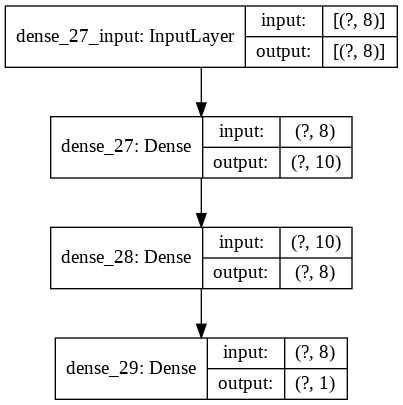

In [0]:
# example of plotting a model
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import plot_model
# define model
model = Sequential()
model.add(Dense(10, activation='relu', kernel_initializer='he_normal', input_shape=(8,)))
model.add(Dense(8, activation='relu', kernel_initializer='he_normal'))
model.add(Dense(1, activation='sigmoid'))
# summarize the model
plot_model(model, 'model.png', show_shapes=True)

## 4.2. How to Plot Model Learning Curves
Learning curves are a plot of neural network model performance over time, such as calculated at the end of each training epoch.

Plots of learning curves provide insight into the learning dynamics of the model, such as whether the model is learning well, whether it is underfitting the training dataset, or whether it is overfitting the training dataset.

You can easily create learning curves for your deep learning models.
First, you must update your call to the fit function to include reference to a validation dataset. This is a portion of the training set not used to fit the model, and is instead used to evaluate the performance of the model during training.

You can split the data manually and specify the validation_data argument, or you can use the validation_split argument and specify a percentage split of the training dataset and let the API perform the split for you. The latter is simpler for now.

The fit function will return a history object that contains a trace of performance metrics recorded at the end of each training epoch. This includes the chosen loss function and each configured metric, such as accuracy, and each loss and metric is calculated for the training and validation datasets.

A learning curve is a plot of the loss on the training dataset and the validation dataset. We can create this plot from the history object using the Matplotlib library.

The example below fits a small neural network on a synthetic binary classification problem. A validation split of 30 percent is used to evaluate the model during training and the cross-entropy loss on the train and validation datasets are then graphed using a line plot.

Running the example fits the model on the dataset. At the end of the run, the history object is returned and used as the basis for creating the line plot.

The cross-entropy loss for the training dataset is accessed via the ‘loss‘ key and the loss on the validation dataset is accessed via the ‘val_loss‘ key on the history attribute of the history object

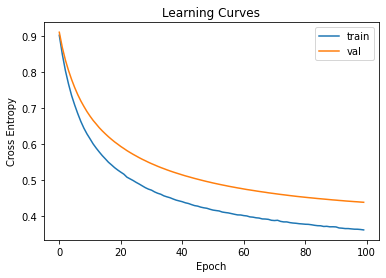

In [0]:
# example of plotting learning curves
from sklearn.datasets import make_classification
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD
from matplotlib import pyplot
# create the dataset
X, y = make_classification(n_samples=1000, n_classes=2, random_state=1)
# determine the number of input features
n_features = X.shape[1]
# define model
model = Sequential()
model.add(Dense(10, activation='relu', kernel_initializer='he_normal', input_shape=(n_features,)))
model.add(Dense(1, activation='sigmoid'))
# compile the model
sgd = SGD(learning_rate=0.001, momentum=0.8)
model.compile(optimizer=sgd, loss='binary_crossentropy')
# fit the model
history = model.fit(X, y, epochs=100, batch_size=32, verbose=0, validation_split=0.3)
# plot learning curves
pyplot.title('Learning Curves')
pyplot.xlabel('Epoch')
pyplot.ylabel('Cross Entropy')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='val')
pyplot.legend()
pyplot.show()

## 4.3. How to Save and Load Your Model
Training and evaluating models is great, but we may want to use a model later without retraining it each time.

This can be achieved by saving the model to file and later loading it and using it to make predictions.

This can be achieved using the ***save()*** function on the model to save the model. It can be loaded later using the ***load_model()*** function.

The model is saved in H5 format, an efficient array storage format. As such, you must ensure that the h5py library is installed on your workstation. This can be achieved using pip; for example:

> pip install h5py

The example below fits a simple model on a synthetic binary classification problem and then saves the model file.

In [0]:
# example of saving a fit model
from sklearn.datasets import make_classification
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD
# create the dataset
X, y = make_classification(n_samples=1000, n_features=4, n_classes=2, random_state=1)
# determine the number of input features
n_features = X.shape[1]
# define model
model = Sequential()
model.add(Dense(10, activation='relu', kernel_initializer='he_normal', input_shape=(n_features,)))
model.add(Dense(1, activation='sigmoid'))
# compile the model
sgd = SGD(learning_rate=0.001, momentum=0.8)
model.compile(optimizer=sgd, loss='binary_crossentropy')
# fit the model
model.fit(X, y, epochs=100, batch_size=32, verbose=0, validation_split=0.3)
# save model to file
model.save('model.h5')

Running the example fits the model and saves it to file with the name ‘model.h5‘.

We can then load the model and use it to make a prediction, or continue training it, or do whatever we wish with it.

The example below loads the model and uses it to make a prediction.
Running the example loads the image from file, then uses it to make a prediction on a new row of data and prints the result.

In [0]:
# example of loading a saved model
from sklearn.datasets import make_classification
from tensorflow.keras.models import load_model
# create the dataset
X, y = make_classification(n_samples=1000, n_features=4, n_classes=2, random_state=1)
# load the model from file
model = load_model('model.h5')
# make a prediction
row = [1.91518414, 1.14995454, -1.52847073, 0.79430654]
yhat = model.predict([row])
print('Predicted: %.3f' % yhat[0])

Predicted: 0.872
